# EDA estrutural — Amazon Product Performance & Customer Insights

Esta investigação examina o arquivo recebido antes de decidir como preparar os dados.
O percurso começa pelos valores originais, testa sua organização e termina nas relações
que a fonte permite sustentar. Conversões e separações são experimentos em memória;
nenhum registro é removido da fonte e nenhum arquivo tratado é produzido.

## 1 — Conhecendo a fonte e as informações disponíveis
### 1.1 — Arquivo, campos e preenchimento
Que informações o catálogo oferece? A prévia mostra três linhas reais e campos selecionados. O inventário cobre as 16 colunas originais. A leitura mantém as regras de tipos e nulos da versão anterior. `source_index` guarda a posição original, a partir de zero.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidatos = [Path('../amazon.csv'), Path('amazon.csv'), Path('amazon_sales_analise/amazon.csv')]
caminho = next((p for p in candidatos if p.is_file()), None)
if caminho is None:
    raise FileNotFoundError('Abra o notebook na pasta do EDA ou na raiz do projeto.')
dados = pd.read_csv(caminho)
colunas_originais = dados.columns.tolist()
dados.insert(0, 'source_index', dados.index)
previa = dados.loc[:2, ['source_index', 'product_id', 'product_name', 'category', 'discounted_price', 'rating']].copy()
for campo in ['product_name', 'category']:
    previa[campo] = previa[campo].str.slice(0, 68) + previa[campo].str.len().gt(68).map({True: '…', False: ''})
previa.T

,0,1,2
source_index,0,1,2
product_id,B07JW9H4J1,B098NS6PVG,B096MSW6CT
product_name,Wayona Nylon Braided USB to Lightning Fast Cha...,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Sounce Fast Phone Charging Cable & Data Sync U...
category,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories|Accessories&Peripherals|...
discounted_price,₹399,₹199,₹199
rating,4.2,4.0,3.9


In [2]:
campos = dados[colunas_originais]
display(pd.DataFrame({'Tipo lido': campos.dtypes.astype(str),
                      'Preenchidos': campos.notna().sum(),
                      'Ausentes': campos.isna().sum()}).rename_axis('Campo'))

,Tipo lido,Preenchidos,Ausentes
Campo,,,
product_id,object,1465,0
product_name,object,1465,0
category,object,1465,0
discounted_price,object,1465,0
actual_price,object,1465,0
discount_percentage,object,1465,0
rating,object,1465,0
rating_count,object,1463,2
about_product,object,1465,0


### 1.2 — Perguntas iniciais da investigação
Dos 16 campos em 1.465 registros, apenas `rating_count` apresenta ausências na leitura (duas). O arquivo traz categorias, medidas comerciais, usuários, reviews, textos e referências digitais, sem campos explícitos de pedido ou data. A primeira questão é se cada posição corresponde a um produto distinto. Em seguida, verificaremos como categorias e medidas se organizam e quais vínculos podem ser recuperados.

## 2 — Investigando os registros e a identidade dos produtos
### 2.1 — O que representa uma linha do arquivo?
Para sair do recorte das primeiras linhas, selecionamos três registros em posições
equidistantes do arquivo. A seleção é ilustrativa, não aleatória nem representativa.
A hipótese inicial é que cada registro descreva um produto; isso ainda não implica
um produto único por linha em todo o arquivo. Nome e categoria aparecem como trechos
de exibição; os valores integrais permanecem em `dados`.

In [3]:
campos_medidas = ['actual_price', 'discounted_price', 'discount_percentage', 'rating', 'rating_count']
campos_produto = ['source_index', 'product_id', 'product_name', 'category'] + campos_medidas
indices_produto = [0, len(dados) // 2, len(dados) - 1]
amostra_produto = dados.loc[indices_produto, campos_produto].copy()
amostra_produto['product_name'] = amostra_produto.product_name.str[:100]
amostra_produto['category'] = amostra_produto.category.str[:90]
with pd.option_context('display.max_colwidth', None):
    display(amostra_produto.rename(columns={'product_name': 'Nome — trecho de exibição',
                                           'category': 'Categoria — trecho de exibição'}).T)

,0,732,1464
source_index,0,732,1464
product_id,B07JW9H4J1,B07Z3K96FR,B01486F4G6
Nome — trecho de exibição,"Wayona Nylon Braided USB to Lightning Fast Charging and Data Sync Cable Compatible for iPhone 13, 12",Robustrion Tempered Glass Screen Protector for iPad 10.2 inch 9th Gen Generation 2021 8th Gen 2020 7,Borosil Jumbo 1000-Watt Grill Sandwich Maker (Black)
Categoria — trecho de exibição,Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables,Computers&Accessories|Accessories&Peripherals|TabletAccessories|ScreenProtectors,Home&Kitchen|Kitchen&HomeAppliances|SmallKitchenAppliances|SandwichMakers
actual_price,"₹1,099","₹1,499","₹3,690"
discounted_price,₹399,₹399,"₹2,863"
discount_percentage,64%,73%,22%
rating,4.2,4.1,4.3
rating_count,"24,269","5,730","6,987"


### 2.2 — Duplicação integral dos registros
O exemplo parece uma descrição de catálogo, mas a identidade exige comparar o conjunto.
Primeiro testamos igualdade das 16 colunas originais. `source_index` fica fora do teste,
pois foi criado para distinguir posições e tornaria toda linha artificialmente única.

In [4]:
duplicatas = dados.duplicated(subset=colunas_originais, keep=False)
duplicatas.sum()

np.int64(0)

Nenhuma linha é integralmente repetida. Isso não resolve a identidade comercial:
uma URL ou uma contagem diferente já impede igualdade completa.

### 2.3 — Unicidade e repetição dos identificadores
Contaremos linhas por `product_id` e examinaremos o primeiro ID repetido na ordem da
fonte. Separar linhas envolvidas e excedentes evita tratar toda repetição como descarte.

In [5]:
frequencia = dados.groupby('product_id', sort=False).size()
ids_repetidos = frequencia[frequencia.gt(1)]
display(pd.Series({
    'product_id distintos': len(frequencia), 'IDs repetidos': len(ids_repetidos),
    'linhas nos IDs repetidos': ids_repetidos.sum(),
    'linhas além de uma por ID': (ids_repetidos - 1).sum()
}))
dados.loc[dados.product_id.eq(ids_repetidos.index[0]), campos_produto].T

product_id distintos         1351
IDs repetidos                  92
linhas nos IDs repetidos      206
linhas além de uma por ID     114
dtype: int64

,0,369,614
source_index,0,369,614
product_id,B07JW9H4J1,B07JW9H4J1,B07JW9H4J1
product_name,Wayona Nylon Braided USB to Lightning Fast Cha...,Wayona Nylon Braided USB to Lightning Fast Cha...,Wayona Nylon Braided USB to Lightning Fast Cha...
category,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories|Accessories&Peripherals|...
actual_price,"₹1,099","₹1,099","₹1,099"
discounted_price,₹399,₹399,₹399
discount_percentage,64%,64%,64%
rating,4.2,4.2,4.2
rating_count,"24,269","24,270","24,269"


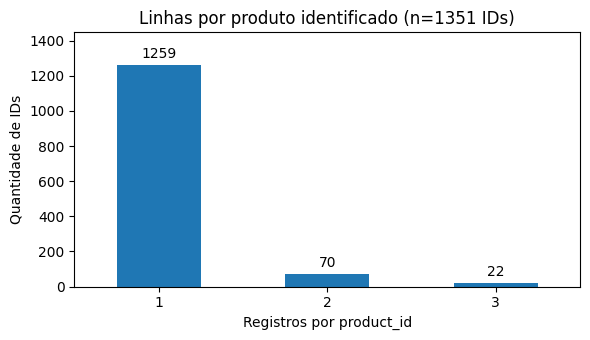

In [6]:
distribuicao_ids = frequencia.value_counts().sort_index()
ax = distribuicao_ids.plot.bar(rot=0, figsize=(6, 3.5))
ax.bar_label(ax.containers[0], padding=3)
ax.set(title=f'Linhas por produto identificado (n={len(frequencia)} IDs)',
       xlabel='Registros por product_id', ylabel='Quantidade de IDs')
ax.set_ylim(0, distribuicao_ids.max() * 1.15)
plt.tight_layout()
plt.show()

A concentração em uma linha convive com 92 IDs repetidos. No exemplo, o mesmo código
reaparece; portanto `product_id` não é a chave do registro físico. Os 114 excedentes
medem repetição da referência, não linhas descartáveis.

### 2.4 — Divergências dentro do mesmo produto
Se as linhas guardarem versões diferentes, uma escolha arbitrária pode perder informação.
Contaremos valores distintos por campo, incluindo ausências como um estado observado.

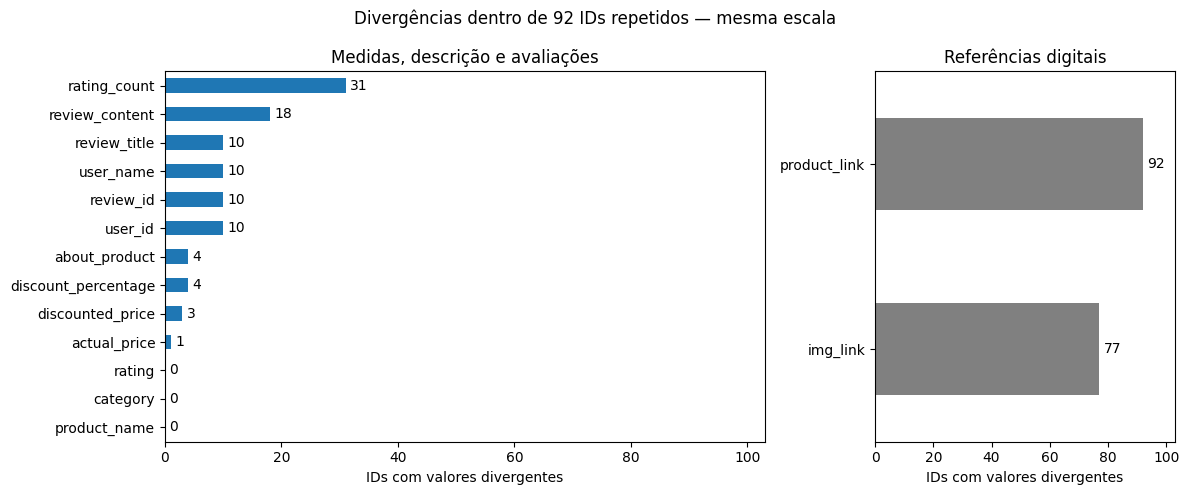

In [7]:
repetidos = dados[dados.product_id.isin(ids_repetidos.index)]
diversidade = repetidos.groupby('product_id')[colunas_originais[1:]].nunique(dropna=False)
conflitos = diversidade.gt(1).sum().sort_values()
campos_links = ['img_link', 'product_link']
fig, eixos = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [2, 1]})
conflitos.drop(campos_links).plot.barh(ax=eixos[0])
conflitos[campos_links].plot.barh(ax=eixos[1], color='gray')
for ax, titulo in zip(eixos, ['Medidas, descrição e avaliações', 'Referências digitais']):
    ax.bar_label(ax.containers[0], padding=3)
    ax.set(title=titulo, xlabel='IDs com valores divergentes', ylabel='')
    ax.set_xlim(0, len(ids_repetidos) * 1.12)
fig.suptitle(f'Divergências dentro de {len(ids_repetidos)} IDs repetidos — mesma escala')
plt.tight_layout()
plt.show()

Links divergem com frequência maior que medidas: uma diferença de URL não implica outro
produto. Nome, categoria e nota permanecem estáveis nos IDs repetidos. Para ver uma
mudança substantiva lado a lado, selecionamos o primeiro ID com preço descontado divergente.

In [8]:
id_preco = diversidade.index[diversidade.discounted_price.gt(1)][0]
dados.loc[dados.product_id.eq(id_preco), ['source_index', 'product_id'] + campos_medidas].set_index('source_index').T

source_index,397,641
product_id,B09MT84WV5,B09MT84WV5
actual_price,"₹3,999","₹3,999"
discounted_price,"₹1,149","₹1,059"
discount_percentage,71%,74%
rating,4.3,4.3
rating_count,"1,40,036","1,40,035"


O exemplo contém preço e contagem diferentes, sem data que determine precedência.
O ID organiza as observações, mas não torna todos os seus atributos intercambiáveis.

### 2.5 — Coincidências entre produtos com IDs diferentes
Testaremos igualdade em 13 campos: nome, categoria, cinco medidas, descrição,
usuários, nomes, IDs de reviews, títulos e conteúdo. Excluímos apenas `product_id`,
`product_link` e `img_link`. O agrupamento compara valores integrais, sem concatenar
assinaturas ou criar códigos de grupo permanentes.

In [9]:
campos_13 = [c for c in colunas_originais if c not in ['product_id', 'product_link', 'img_link']]
grupos_13 = dados.groupby(campos_13, dropna=False, sort=False)
tamanhos_13 = grupos_13.size()
ids_13 = grupos_13.product_id.nunique()
cruzados_13 = grupos_13.filter(lambda g: g.product_id.nunique() > 1)
display(pd.Series({
    'grupos com 13 campos iguais': tamanhos_13.gt(1).sum(),
    'linhas nesses grupos': tamanhos_13[tamanhos_13.gt(1)].sum(),
    'grupos envolvendo IDs diferentes': ids_13.gt(1).sum(),
    'registros envolvendo IDs diferentes': len(cruzados_13)
}))
cruzados_13.groupby(campos_13, dropna=False, sort=False).agg(
    origens=('source_index', list), ids=('product_id', list)
).reset_index()[['product_name', 'origens', 'ids']]

grupos com 13 campos iguais             61
linhas nesses grupos                   133
grupos envolvendo IDs diferentes         6
registros envolvendo IDs diferentes     13
dtype: int64

,product_name,origens,ids
0,"Smashtronics® - Case for Firetv Remote, Fire S...","[243, 296]","[B09L835C3V, B09HK9JH4F]"
1,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...","[334, 380]","[B0BF57RN3K, B0BF54LXW6]"
2,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...","[364, 368]","[B0BF54972T, B0BF563HB4]"
3,"Samsung Galaxy M33 5G (Emerald Brown, 6GB, 128...","[366, 411]","[B09TWH8YHM, B0B14MR9L1]"
4,"Samsung Galaxy M13 5G (Aqua Green, 6GB, 128GB ...","[399, 425, 481]","[B0B4F3QNDM, B0B4F5L738, B0B4F1YC3J]"
5,"Redmi Note 11 (Horizon Blue, 6GB RAM, 64GB Sto...","[501, 554]","[B09QS9X9L8, B09QS9CWLV]"


O primeiro grupo que atravessa IDs ajuda a localizar a diferença. Os 13 campos foram comparados integralmente, inclusive os textos que não aparecem na prévia.

In [10]:
exemplo_13 = cruzados_13.groupby(campos_13, dropna=False, sort=False).get_group(
    tuple(cruzados_13.iloc[0][campos_13])
)
comparacao_13 = exemplo_13[['source_index', 'product_id'] + campos_medidas].copy()
comparacao_13['Link — trecho de exibição'] = exemplo_13.product_link.str.split('/dp/', regex=False).str[-1]
comparacao_13['Mesma URL de imagem da primeira linha'] = exemplo_13.img_link.eq(exemplo_13.img_link.iloc[0])
with pd.option_context('display.max_colwidth', None):
    display(comparacao_13.set_index('source_index').T)

source_index,243,296
product_id,B09L835C3V,B09HK9JH4F
actual_price,₹399,₹399
discounted_price,₹199,₹199
discount_percentage,50%,50%
rating,4.2,4.2
rating_count,"1,335","1,335"
Link — trecho de exibição,B09L835C3V/ref=sr_1_276?qid=1672909138&s=electronics&sr=1-276,B09HK9JH4F/ref=sr_1_463?qid=1672909147&s=electronics&sr=1-463
Mesma URL de imagem da primeira linha,True,True


Os 61 grupos ocupam 133 linhas, mas apenas seis grupos atravessam IDs. A igualdade dos
13 campos é uma evidência de similaridade, não prova de identidade comercial. Os campos
excluídos continuam preservando códigos e referências diferentes.

### 2.6 — Limites do nome e da descrição como identificadores
O nome foi estável dentro dos IDs. Testaremos o sentido inverso: um nome exato pode estar
associado a mais de um ID? Depois observaremos descrições originais antes de separá-las.
O recorte seguinte usa os dois primeiros nomes compartilhados em ordem alfabética; `nomes_compartilhados` conserva a relação completa.

In [11]:
ids_por_nome = dados.groupby('product_name').product_id.nunique()
nomes_compartilhados = ids_por_nome[ids_por_nome.gt(1)]
exemplos_nomes = dados[dados.product_name.isin(nomes_compartilhados.head(2).index)]
with pd.option_context('display.max_colwidth', None):
    display(exemplos_nomes[['source_index', 'product_id', 'discounted_price']].assign(
        nome_trecho_exibicao=exemplos_nomes.product_name.str[:100]
    ))
len(nomes_compartilhados)

,source_index,product_id,discounted_price,nome_trecho_exibicao
334,334,B0BF57RN3K,"₹1,799","Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Watch with Bluetooth Calling, AI Voice Assistance, 100 Sp"
364,364,B0BF54972T,"₹1,799","Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Watch with Bluetooth Calling, AI Voice Assistance, 100 Sp"
365,365,B09YV4MW2T,"₹2,199","Fire-Boltt India's No 1 Smartwatch Brand Talk 2 Bluetooth Calling Smartwatch with Dual Button, Hands"
368,368,B0BF563HB4,"₹1,799","Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Watch with Bluetooth Calling, AI Voice Assistance, 100 Sp"
372,372,B0BF4YBLPX,"₹1,799","Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Watch with Bluetooth Calling, AI Voice Assistance, 100 Sp"
380,380,B0BF54LXW6,"₹1,799","Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Watch with Bluetooth Calling, AI Voice Assistance, 100 Sp"
484,484,B09YV3K34W,"₹2,199","Fire-Boltt India's No 1 Smartwatch Brand Talk 2 Bluetooth Calling Smartwatch with Dual Button, Hands"
611,611,B09YV4MW2T,"₹2,199","Fire-Boltt India's No 1 Smartwatch Brand Talk 2 Bluetooth Calling Smartwatch with Dual Button, Hands"


9

Nove nomes exatos aparecem em IDs distintos; nome comercial não é uma chave segura.
Na descrição, selecionamos o primeiro ID com versões diferentes e mostramos o início de cada versão como trecho de exibição. Assim podemos avaliar se `|` separa características e onde os textos divergem.

In [12]:
id_descricao = diversidade.index[diversidade.about_product.gt(1)][0]
exemplo_descricao = dados.loc[dados.product_id.eq(id_descricao), ['source_index', 'product_id', 'about_product']]
with pd.option_context('display.max_colwidth', None):
    display(exemplo_descricao[['source_index', 'product_id']].assign(
        descricao_trecho_exibicao=exemplo_descricao.about_product.str[:180]
    ))

,source_index,product_id,descricao_trecho_exibicao
433,433,B07DJLFMPS,"HP 32GB Class 10 MicroSD Memory Card (U1 TF Card 32GB)|Class 10, UHS-I, U1 Memory Card with Adapter|Perfect for storing and transferring more mobile content across your devices, in"
686,686,B07DJLFMPS,"Class 10, UHS-I, U1 Memory Card with Adapter|Perfect for storing and transferring more mobile content across your devices, including photos, music and movies for entertainment or a"


As versões de `B07DJLFMPS` diferem já na frase inicial. O delimitador parece separar
características, não níveis de classificação. Vamos testar sua presença e mostrar a
separação experimental de uma descrição, sem transformá-la em atributos definitivos.

In [13]:
display(pd.Series({
    'descrições com |': dados.about_product.str.contains('|', regex=False).sum(),
    'menor extensão': dados.about_product.str.len().min(),
    'mediana de caracteres': dados.about_product.str.len().median(),
    'maior extensão': dados.about_product.str.len().max(),
    'IDs com descrições divergentes': conflitos['about_product']
}))
pd.Series(exemplo_descricao.about_product.iloc[0].split('|'), name='Características aparentes')

descrições com |                  1422.0
menor extensão                       5.0
mediana de caracteres              645.0
maior extensão                    2646.0
IDs com descrições divergentes       4.0
dtype: float64

0    HP 32GB Class 10 MicroSD Memory Card (U1 TF Ca...
1         Class 10, UHS-I, U1 Memory Card with Adapter
2    Perfect for storing and transferring more mobi...
3    Ideal for the latest tablets, PCs, smartphones...
4    16-128GB: Read speed up to 80MB/s, write minum...
5    Importer Details: Fortune marketing Pvt Ltd D1...
6                            Country of Origin: Taiwan
Name: Características aparentes, dtype: object

### 2.7 — Conclusões sobre a identidade dos produtos
`product_id` identifica o produto no catálogo. `source_index` distingue as ocorrências. Nomes compartilhados e quatro IDs com descrições divergentes impedem usar esses atributos como chaves. O Notebook 02 preserva todas as ocorrências e escolhe uma referência comercial rastreável por produto. Antes disso, precisamos verificar se a categoria também varia dentro do ID.

## 3 — Compreendendo as categorias e suas classificações
### 3.1 — Estrutura original das categorias
A categoria observada junto ao produto contém barras e rótulos. Para inspecionar
caminhos contrastantes, contamos segmentos aparentes separados por `|` e escolhemos
um com a menor e outro com a maior quantidade, além de um contendo vírgula.
Essa contagem orienta a amostra; o significado hierárquico ainda precisa ser examinado.

In [14]:
segmentos_aparentes = dados.category.str.count(r'\|') + 1
indices_categoria = [segmentos_aparentes.idxmin(), segmentos_aparentes.idxmax(),
                     dados.index[dados.category.str.contains(',', regex=False)][0]]
with pd.option_context('display.max_colwidth', None):
    display(dados.loc[indices_categoria, ['source_index', 'product_id', 'category']].assign(
        segmentos_aparentes=segmentos_aparentes.loc[indices_categoria]
    ))

,source_index,product_id,category,segmentos_aparentes
662,662,B08HLZ28QC,Computers&Accessories|NetworkingDevices,2
616,616,B07KCMR8D6,"OfficeProducts|OfficePaperProducts|Paper|Stationery|Pens,Pencils&WritingSupplies|Pens&Refills|GelInkRollerballPens",7
12,12,B07KSMBL2H,"Electronics|HomeTheater,TV&Video|Accessories|Cables|HDMICables",5


### 3.2 — Identificação da hierarquia
Os exemplos contêm `|`, enquanto a vírgula aparece dentro de rótulos como
`HomeTheater,TV&Video`. A hipótese é que as barras separem segmentos ordenados do
mais geral ao mais específico. Vamos comparar o texto original com a divisão literal.

In [15]:
partes_categoria = dados.category.str.split('|', regex=False)
categorias = dados[['source_index', 'product_id', 'category']].copy()
categorias['profundidade'] = partes_categoria.str.len()
categorias['principal'] = partes_categoria.str[0]
categorias['nivel_2'] = partes_categoria.str[1]
categorias['final'] = partes_categoria.apply(lambda partes: next((p for p in reversed(partes) if p.strip()), None))
niveis = pd.DataFrame(partes_categoria.tolist(), index=dados.index)
niveis.columns = range(1, len(niveis.columns) + 1)
amostra_niveis = niveis.loc[indices_categoria].rename(index=lambda i: f'Origem {i}').T
display(amostra_niveis.fillna('—').rename_axis('Nível'))

,Origem 662,Origem 616,Origem 12
Nível,,,
1,Computers&Accessories,OfficeProducts,Electronics
2,NetworkingDevices,OfficePaperProducts,"HomeTheater,TV&Video"
3,—,Paper,Accessories
4,—,Stationery,Cables
5,—,"Pens,Pencils&WritingSupplies",HDMICables
6,—,Pens&Refills,—
7,—,GelInkRollerballPens,—


Os nomes e posições sustentam uma taxonomia aparente: grupos amplos antecedem classes
específicas nos exemplos. Isso não valida externamente uma taxonomia oficial.

### 3.3 — Profundidade e diversidade dos níveis
Quantas posições aparecem e quantos rótulos distintos há em cada uma? O quadro inclui
segmentos vazios para testar se a separação esconde lacunas; as posições existem somente
na variável temporária `niveis`; o travessão da amostra indica posição inexistente, não um segmento vazio.

,rótulos distintos,linhas com posição,segmentos vazios
Posição,,,
1,9,1465,0
2,29,1465,0
3,71,1457,0
4,136,1300,0
5,56,522,0
6,14,85,0
7,7,13,0


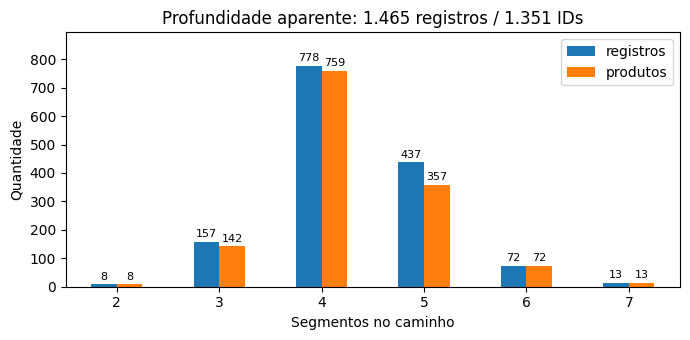

In [16]:
display(pd.DataFrame({
    'rótulos distintos': niveis.nunique(),
    'linhas com posição': niveis.notna().sum(),
    'segmentos vazios': niveis.eq('').sum()
}).rename_axis('Posição'))
profundidades = categorias.groupby('profundidade').agg(registros=('source_index', 'size'), produtos=('product_id', 'nunique'))
ax = profundidades.plot.bar(rot=0, figsize=(7, 3.5))
ax.set(title='Profundidade aparente: 1.465 registros / 1.351 IDs',
       xlabel='Segmentos no caminho', ylabel='Quantidade')
for barras in ax.containers:
    ax.bar_label(barras, padding=2, fontsize=8)
ax.set_ylim(0, profundidades.to_numpy().max() * 1.15)
plt.tight_layout()
plt.show()

A profundidade varia de dois a sete níveis, sem segmentos vazios. A variação não é
ausência de estrutura: significa que uma posição fixa não representa sempre a mesma
especificidade. Por isso o último segmento será obtido de cada caminho.

### 3.4 — Organização dos ramos e subcategorias
Como os registros se distribuem entre os ramos observados? A comparação entre linhas e
IDs torna visível onde a repetição muda a composição. As subcategorias permanecem
acompanhadas do primeiro nível para não perder seu contexto.

In [17]:
principais = categorias.groupby('principal').agg(registros=('source_index', 'size'), produtos=('product_id', 'nunique'))
display(principais)

,registros,produtos
principal,,
Car&Motorbike,1,1
Computers&Accessories,453,375
Electronics,526,490
Health&PersonalCare,1,1
Home&Kitchen,448,448
HomeImprovement,2,2
MusicalInstruments,2,2
OfficeProducts,31,31
Toys&Games,1,1


In [18]:
subcategorias = categorias.groupby(['principal', 'nivel_2']).agg(
    registros=('source_index', 'size'), produtos=('product_id', 'nunique'), caminhos=('category', 'nunique')
).sort_values('produtos', ascending=False)
display(subcategorias.groupby(level=0).agg(ramos=('caminhos', 'size'), caminhos=('caminhos', 'sum')))

,ramos,caminhos
principal,,
Car&Motorbike,1,1
Computers&Accessories,8,57
Electronics,9,62
Health&PersonalCare,1,1
Home&Kitchen,5,72
HomeImprovement,1,2
MusicalInstruments,1,1
OfficeProducts,2,14
Toys&Games,1,1


O quadro mostra quantos ramos de segundo nível e caminhos completos existem sob cada categoria principal. A posição na hierarquia é necessária para interpretar o rótulo mais específico.

### 3.5 — Caminho completo e rótulos finais
O último segmento identifica sozinho a classificação? Contamos os caminhos distintos que compartilham cada rótulo final e exibimos os casos de colisão.

In [19]:
ramos_por_final = categorias.groupby('final').category.nunique()
display(pd.Series({
    'categorias principais': categorias.principal.nunique(),
    'caminhos completos': categorias.category.nunique(),
    'rótulos finais distintos': categorias.final.nunique(),
    'rótulos finais em vários caminhos': ramos_por_final.gt(1).sum()
}))
with pd.option_context('display.max_colwidth', None):
    display(categorias.loc[categorias.final.isin(ramos_por_final[ramos_por_final.gt(1)].index),
                           ['final', 'category']].drop_duplicates())

categorias principais                  9
caminhos completos                   211
rótulos finais distintos             207
rótulos finais em vários caminhos      4
dtype: int64

,final,category
218,Adapters,Electronics|HomeAudio|Accessories|Adapters
404,Stands,Electronics|Mobiles&Accessories|MobileAccessories|Stands
447,ScreenProtectors,"Electronics|Mobiles&Accessories|MobileAccessories|Maintenance,Upkeep&Repairs|ScreenProtectors"
552,Adapters,"Electronics|Headphones,Earbuds&Accessories|Adapters"
732,ScreenProtectors,Computers&Accessories|Accessories&Peripherals|TabletAccessories|ScreenProtectors
787,Cases,"Electronics|Headphones,Earbuds&Accessories|Cases"
803,Stands,Computers&Accessories|Accessories&Peripherals|TabletAccessories|Stands
848,Cases,"Computers&Accessories|Accessories&Peripherals|TabletAccessories|Bags,Cases&Sleeves|Cases"


São 207 rótulos finais em 211 caminhos. `Adapters`, `Cases`, `ScreenProtectors` e `Stands` aparecem em mais de um caminho. O caminho integral preserva as distinções. A próxima verificação é se cada produto mantém a mesma classificação entre ocorrências.

### 3.6 Consistência por ID e grupos pequenos
A classificação é estável dentro do mesmo código? Vamos contar caminhos por ID e
examinar os menores grupos principais. Um grupo pequeno pode produzir estatísticas
instáveis em análises futuras, mesmo que sua classificação esteja consistente.

In [20]:
caminhos_por_id = categorias.groupby('product_id').category.nunique()
display(caminhos_por_id.value_counts().rename_axis('Caminhos por ID').rename('IDs'))
principais[principais.produtos.le(2)].sort_values('produtos')

Caminhos por ID
1    1351
Name: IDs, dtype: int64

,registros,produtos
principal,,
Car&Motorbike,1,1
Health&PersonalCare,1,1
Toys&Games,1,1
HomeImprovement,2,2
MusicalInstruments,2,2


### 3.7 — Diretrizes para classificação e comparação
Cada ID observado mantém um caminho; cinco categorias principais têm apenas um ou dois
IDs. O caminho completo deve ser preservado e o nível de análise precisa ser escolhido
com denominadores explícitos. As divisões acima são temporárias: não foi criado um
modelo definitivo com sete colunas fixas.

## 4 — Medidas comerciais e avaliações agregadas
### 4.1 — Representação original das medidas
Como preços, percentuais e avaliações estão representados? Ao lado dos primeiros registros,
exibimos notas que não seguem um padrão decimal e contagens ausentes. A seleção procura
formatos diferentes antes de converter os valores.

In [21]:
formato_nota = dados.rating.str.fullmatch(r'\d+(\.\d+)?', na=False)
exemplos_medidas = pd.concat([dados.head(2), dados.loc[~formato_nota | dados.rating_count.isna()]])
exemplos_medidas[['source_index', 'product_id'] + campos_medidas]

,source_index,product_id,actual_price,discounted_price,discount_percentage,rating,rating_count
0,0,B07JW9H4J1,"₹1,099",₹399,64%,4.2,"24,269"
1,1,B098NS6PVG,₹349,₹199,43%,4.0,"43,994"
282,282,B0B94JPY2N,₹999,₹199,80%,3.0,NaN
324,324,B0BQRJ3C47,₹999,₹249,75%,5.0,NaN
1279,1279,B08L12N5H1,"₹2,499","₹2,099",16%,|,992


### 4.2 Conversão exploratória e qualidade
O símbolo `₹` indica rupias, `%` marca percentuais e vírgulas separam milhares, inclusive
na notação indiana. A nota literal `|` não é numérica; ausência não equivale a zero.
Vamos retirar apenas esses marcadores nas cópias em memória, usando coerção para localizar
falhas. O quadro distingue ausência na fonte, falha de conversão e validade de domínio.
Preço original deve ser positivo; preço descontado pode ser zero (desconto integral), mas não negativo. A relação entre os dois preços será verificada separadamente em 4.5.

In [22]:
numeros = pd.DataFrame(index=dados.index)
for campo in campos_medidas:
    texto = dados[campo].str.replace('₹', '', regex=False).str.replace(',', '', regex=False).str.replace('%', '', regex=False)
    numeros[campo] = pd.to_numeric(texto, errors='coerce')
dominio = pd.DataFrame({
    'actual_price': numeros.actual_price.gt(0),
    'discounted_price': numeros.discounted_price.ge(0),
    'discount_percentage': numeros.discount_percentage.between(0, 100),
    'rating': numeros.rating.between(1, 5),
    'rating_count': numeros.rating_count.ge(0) & numeros.rating_count.mod(1).eq(0)
})
qualidade = pd.DataFrame({
    'válidos no domínio': dominio.sum(),
    'ausentes na fonte': dados[campos_medidas].isna().sum(),
    'falhas de conversão': (dados[campos_medidas].notna() & numeros.isna()).sum(),
    'numéricos fora do domínio': (numeros.notna() & ~dominio).sum()
})
qualidade

,válidos no domínio,ausentes na fonte,falhas de conversão,numéricos fora do domínio
actual_price,1465,0,0,0
discounted_price,1465,0,0,0
discount_percentage,1465,0,0,0
rating,1464,0,1,0
rating_count,1463,2,0,0


A conversão deixa uma nota inválida e duas contagens ausentes, sem imputação. Os demais
valores respeitam os domínios testados. Isso valida formatos e faixas, não a veracidade
de cada medida informada.

### 4.3 — Amplitude e assimetria das medidas comerciais
Um resumo conjunto evita repetir cinco tabelas descritivas. O histograma de preços usa
intervalos logarítmicos e eixo x logarítmico para mostrar a cauda; zero não cabe nessa
escala. O gráfico percentual permanece em escala linear.
A escala logarítmica muda apenas a posição no eixo e os intervalos de leitura; os números originais não são transformados e não há dimensão temporal.

In [23]:
numeros.describe().loc[['count', 'min', '25%', '50%', '75%', 'max']].T

,count,min,25%,50%,75%,max
actual_price,1465.0,39.0,800.0,1650.0,4295.0,139900.0
discounted_price,1465.0,39.0,325.0,799.0,1999.0,77990.0
discount_percentage,1465.0,0.0,32.0,50.0,63.0,94.0
rating,1464.0,2.0,4.0,4.1,4.3,5.0
rating_count,1463.0,2.0,1186.0,5179.0,17336.5,426973.0


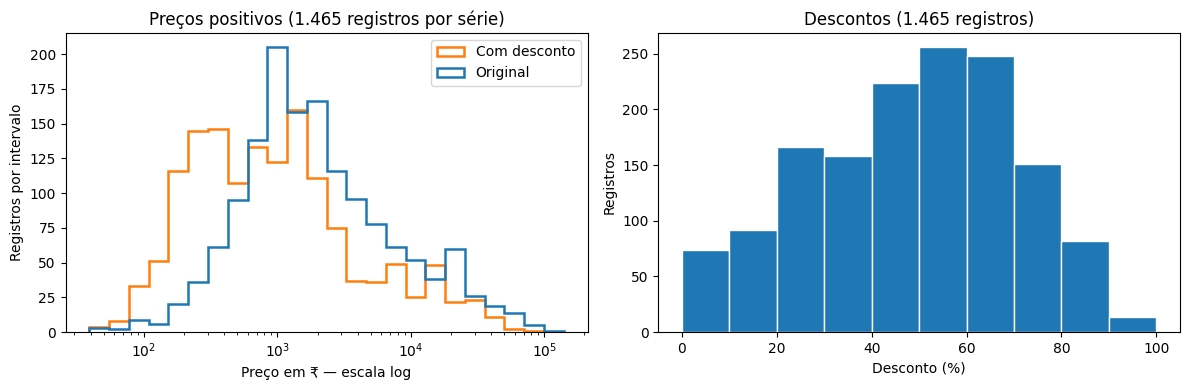

In [24]:
precos = numeros[['actual_price', 'discounted_price']]
limites = np.geomspace(precos[precos.gt(0)].min().min(), precos.max().max(), 25)
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].hist([precos.actual_price[precos.actual_price.gt(0)], precos.discounted_price[precos.discounted_price.gt(0)]],
              bins=limites, label=['Original', 'Com desconto'], histtype='step', linewidth=1.8)
eixos[0].set_xscale('log')
eixos[0].set(title='Preços positivos (1.465 registros por série)', xlabel='Preço em ₹ — escala log', ylabel='Registros por intervalo')
eixos[0].legend()
eixos[1].hist(numeros.discount_percentage, bins=np.arange(0, 101, 10), edgecolor='white')
eixos[1].set(title='Descontos (1.465 registros)', xlabel='Desconto (%)', ylabel='Registros')
plt.tight_layout()
plt.show()

Os preços cobrem ordens de grandeza diferentes; a mediana fica bem abaixo dos extremos.
Isso pede contextualização, não exclusão automática. Para identificar os extremos reais,
exibimos os registros de maior preço original e maior contagem agregada.

In [25]:
indices_extremos = [numeros.actual_price.idxmax(), numeros.rating_count.idxmax()]
with pd.option_context('display.max_colwidth', 160):
    display(dados.loc[indices_extremos, ['source_index', 'product_id', 'product_name'] + campos_medidas].T)

,249,12
source_index,249,12
product_id,B09WN3SRC7,B07KSMBL2H
product_name,Sony Bravia 164 cm (65 inches) 4K Ultra HD Smart LED Google TV KD-65X74K (Black),"AmazonBasics Flexible Premium HDMI Cable (Black, 4K@60Hz, 18Gbps), 3-Foot"
actual_price,"₹1,39,900",₹700
discounted_price,"₹77,990",₹219
discount_percentage,44%,69%
rating,4.7,4.4
rating_count,"5,935","4,26,973"


### 4.4 — Distribuição de notas e contagens agregadas
A distribuição de notas é discreta. Para `rating_count`, a cauda longa pede intervalos
logarítmicos. Os denominadores excluem somente os valores não convertíveis em cada campo;
`rating_count` não representa compras nem o número de comentários disponíveis.

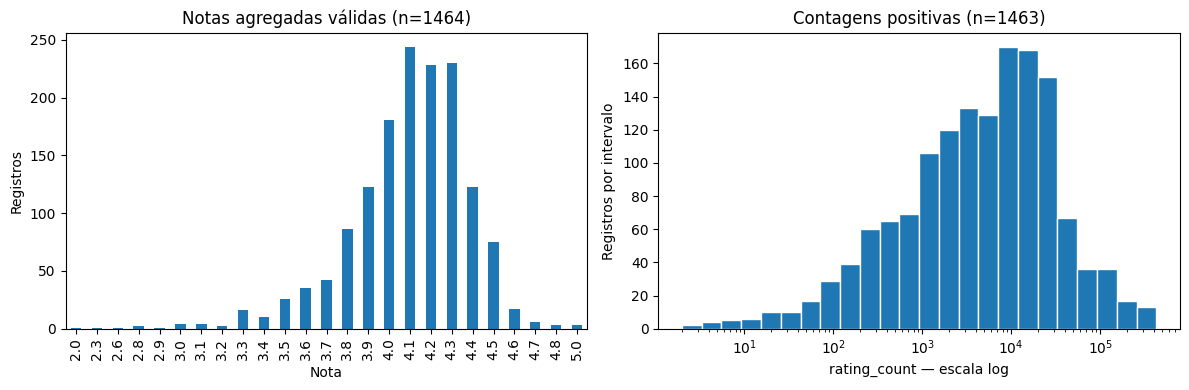

In [26]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
numeros.rating.value_counts().sort_index().plot.bar(ax=eixos[0], rot=90)
eixos[0].set(title=f'Notas agregadas válidas (n={numeros.rating.count()})', xlabel='Nota', ylabel='Registros')
contagens = numeros.rating_count.dropna()
eixos[1].hist(contagens[contagens.gt(0)], bins=np.geomspace(contagens.min(), contagens.max(), 25), edgecolor='white')
eixos[1].set_xscale('log')
eixos[1].set(title=f'Contagens positivas (n={len(contagens)})', xlabel='rating_count — escala log', ylabel='Registros por intervalo')
plt.tight_layout()
plt.show()

As notas se concentram próximas de quatro, enquanto as contagens têm grande dispersão.
São distribuições por registro; não representam automaticamente produtos únicos ou
avaliações individuais. A seção 8 examinará o efeito de mudar a unidade.

### 4.5 — Consistência entre preços e descontos
O percentual informado poderia ser a redução entre os dois preços, arredondada.
Testamos essa hipótese com tolerância explícita de 0,5 ponto percentual.

In [27]:
desconto_calculado = 100 * (1 - numeros.discounted_price / numeros.actual_price)
erro_pp = (desconto_calculado - numeros.discount_percentage).abs()
pd.Series({
    'registros testados': erro_pp.notna().sum(),
    'dentro de 0,5 p.p.': erro_pp.le(0.5).sum(),
    'fora da tolerância': erro_pp.gt(0.5).sum(),
    'maior diferença em p.p.': erro_pp.max(),
    'preço com desconto maior que original': numeros.discounted_price.gt(numeros.actual_price).sum()
})

registros testados                       1465.0
dentro de 0,5 p.p.                       1465.0
fora da tolerância                          0.0
maior diferença em p.p.                     0.5
preço com desconto maior que original       0.0
dtype: float64

Todos os registros atendem à tolerância e nenhum preço com desconto supera o original.
A coerência aritmética não torna os valores invariantes dentro do mesmo ID.

### 4.6 — Estabilidade das medidas por produto
Reaproveitamos a comparação da seção 2. O quadro abaixo confronta um ID com medidas
estáveis e outro com mudanças. A seleção segue o número de valores distintos nas cinco
medidas, sem presumir qual observação é mais recente.

In [28]:
id_estavel = diversidade.index[diversidade[campos_medidas].eq(1).all(axis=1)][0]
dados.loc[dados.product_id.isin([id_estavel, id_preco]), ['source_index', 'product_id'] + campos_medidas].sort_values(['product_id', 'source_index'])

,source_index,product_id,actual_price,discounted_price,discount_percentage,rating,rating_count
46,46,B002PD61Y4,"₹1,208",₹507,58%,4.1,"8,131"
881,881,B002PD61Y4,"₹1,208",₹507,58%,4.1,"8,131"
397,397,B09MT84WV5,"₹3,999","₹1,149",71%,4.3,"1,40,036"
641,641,B09MT84WV5,"₹3,999","₹1,059",74%,4.3,"1,40,035"


O contraste explica a decisão do Notebook 02 de escolher as medidas em conjunto, a partir de uma ocorrência real, preservando as alternativas e a origem. A fonte não fornece cronologia para ordenar as versões. A seguir, examinamos os códigos de usuário presentes nessas mesmas ocorrências.

## 5 — Estrutura e identidade dos usuários
### 5.1 — Organização original dos identificadores
O primeiro registro sugere vários códigos na mesma célula. Contrastamos esse valor
original com o primeiro registro sem vírgula em `user_id`. A seleção usa o delimitador
visível; ainda não pressupõe que as partes sejam usuários distintos. Os dois valores
abaixo estão completos, e a divisão experimental virá em seguida.

In [29]:
indices_usuarios = [dados.index[0], dados.index[~dados.user_id.str.contains(',', regex=False)][0]]
with pd.option_context('display.max_colwidth', None):
    display(dados.loc[indices_usuarios, ['source_index', 'product_id', 'user_id']])

,source_index,product_id,user_id
0,0,B07JW9H4J1,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBBSNLYT3ONILA,AHCTC6ULH4XB6YHDY6PCH2R772LQ,AGYHHIERNXKA6P5T7CZLXKVPT7IQ,AG4OGOFWXJZTQ2HKYIOCOY3KXF2Q,AENGU523SXMOS7JPDTW52PNNVWGQ,AEQJHCVTNINBS4FKTBGQRQTGTE5Q,AFC3FFC5PKFF5PMA52S3VCHOZ5FQ"
155,155,B09XJ1LM7R,AE242TR3GQ6TYC6W4SJ5UYYKBTYQ


### 5.2 — Separação e validação dos códigos de usuário
As vírgulas parecem delimitar códigos de usuário. Testaremos a divisão sem descartar
partes vazias; `explode` mantém origem e produto, e a posição começa em 1. A adequação desse procedimento para nomes livres será examinada separadamente.

In [30]:
listas_usuarios = dados.user_id.str.split(',')
usuarios = dados[['source_index', 'product_id']].assign(user_id=listas_usuarios).explode('user_id', ignore_index=True)
usuarios['user_id'] = usuarios.user_id.str.strip()
usuarios['posicao'] = usuarios.groupby('source_index').cumcount() + 1
display(usuarios[usuarios.source_index.isin(indices_usuarios)])
pd.Series({
    'ocorrências': len(usuarios), 'IDs distintos': usuarios.user_id.nunique(),
    'partes vazias': usuarios.user_id.eq('').sum(),
    'IDs fora do padrão alfanumérico observado': (~usuarios.user_id.str.fullmatch(r'[A-Z0-9]+')).sum()
})

,source_index,product_id,user_id,posicao
0,0,B07JW9H4J1,AG3D6O4STAQKAY2UVGEUV46KN35Q,1
1,0,B07JW9H4J1,AHMY5CWJMMK5BJRBBSNLYT3ONILA,2
2,0,B07JW9H4J1,AHCTC6ULH4XB6YHDY6PCH2R772LQ,3
3,0,B07JW9H4J1,AGYHHIERNXKA6P5T7CZLXKVPT7IQ,4
4,0,B07JW9H4J1,AG4OGOFWXJZTQ2HKYIOCOY3KXF2Q,5
5,0,B07JW9H4J1,AENGU523SXMOS7JPDTW52PNNVWGQ,6
6,0,B07JW9H4J1,AEQJHCVTNINBS4FKTBGQRQTGTE5Q,7
7,0,B07JW9H4J1,AFC3FFC5PKFF5PMA52S3VCHOZ5FQ,8
1231,155,B09XJ1LM7R,AE242TR3GQ6TYC6W4SJ5UYYKBTYQ,1


ocorrências                                  11503
IDs distintos                                 9050
partes vazias                                    0
IDs fora do padrão alfanumérico observado        0
dtype: int64

A separação produz códigos não vazios e alfanuméricos. Isso sustenta individualizar
identificadores, sem afirmar que cada código corresponde a uma pessoa real distinta.

### 5.3 — Multiplicidade e compartilhamento entre produtos
Quantos IDs há por linha e quantos produtos distintos se associam a cada código?
O segundo gráfico conta produtos, não ocorrências repetidas do mesmo produto.

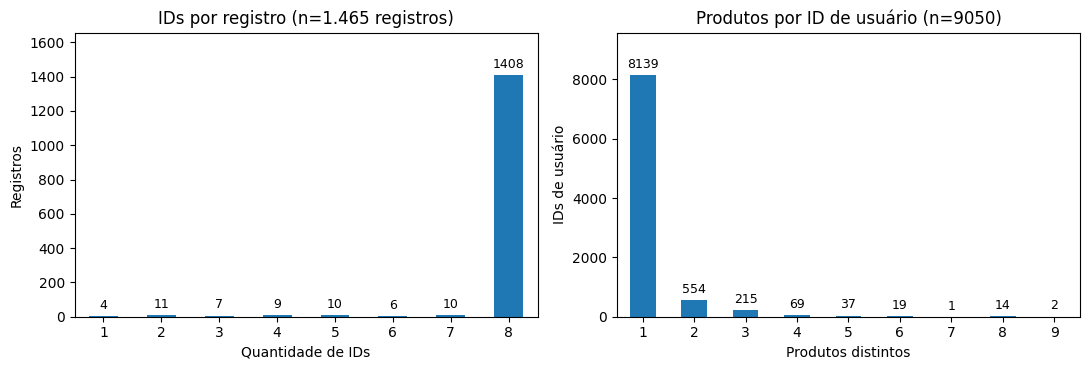

In [31]:
produtos_por_usuario = usuarios.groupby('user_id').product_id.nunique()
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8))
listas_usuarios.str.len().value_counts().sort_index().plot.bar(ax=eixos[0], rot=0)
eixos[0].set(title='IDs por registro (n=1.465 registros)', xlabel='Quantidade de IDs', ylabel='Registros')
produtos_por_usuario.value_counts().sort_index().plot.bar(ax=eixos[1], rot=0)
eixos[1].set(title=f'Produtos por ID de usuário (n={len(produtos_por_usuario)})', xlabel='Produtos distintos', ylabel='IDs de usuário')
for ax in eixos:
    ax.bar_label(ax.containers[0], padding=3, fontsize=9)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
plt.tight_layout()
plt.show()

Predominam oito códigos por linha, mas há registros menores. Parte dos códigos reaparece
entre produtos. Antes de atribuir nomes a esses códigos, precisamos testar se a vírgula
tem a mesma função no campo textual.

### 5.4 — Nomes associados e casos ambíguos
Primeiro mostramos exemplos originais com vírgulas internas aparentes e um separador
duplo. Os índices 107, 164 e 1092 são casos reais de complementos e partes vazias.

In [32]:
with pd.option_context('display.max_colwidth', None):
    display(dados.loc[[107, 164, 1092], ['source_index', 'product_id', 'user_name']])

,source_index,product_id,user_name
107,107,B0981XSZJ7,"AkashP.,Hrishikesh, pune,ROHIT RANJAN ROUT,Sarika Roy,vijay,Dnyanoba Phad,Amazon Customer,Prakash Waghchaure"
164,164,B084N18QZY,"Khan, BA,Vaibhav,ANIL KUMAR AR,aditya,Renga C,Amazon Customer,K J Sudarshan,A.M."
1092,1092,B07MKMFKPG,"ZenGirl,Athulya,Shrinivas C.,Sinduja,Bibek Narayan Mantry,Puneet Khanna,Neeraj,,Amazon Customer"


`Hrishikesh, pune`, `Khan, BA` e `Neeraj,,Amazon Customer` mostram por que dividir nomes
pode criar partes sem identidade própria. Testaremos quantidades e formaremos pares
somente onde as contagens coincidem; essa é uma condição necessária, não prova semântica.

In [33]:
listas_nomes = dados.user_name.str.split(',')
nomes_plausiveis = listas_nomes.str.len().eq(listas_usuarios.str.len())
display(dados.loc[~nomes_plausiveis, ['source_index', 'product_id']].assign(
    ids=listas_usuarios.str.len(), partes_nome=listas_nomes.str.len()
))
pares_nomes = dados.loc[nomes_plausiveis, ['source_index', 'product_id']].assign(
    user_id=listas_usuarios[nomes_plausiveis], nome=listas_nomes[nomes_plausiveis]
).explode(['user_id', 'nome'], ignore_index=True)
pares_nomes['posicao'] = pares_nomes.groupby('source_index').cumcount() + 1
pares_nomes['user_id'] = pares_nomes.user_id.str.strip()
pares_nomes['nome'] = pares_nomes.nome.str.strip()
pares_nomes.head(8)

,source_index,product_id,ids,partes_nome
5,5,B08Y1TFSP6,8,9
35,35,B08Y1SJVV5,8,9
67,67,B0B9XN9S3W,8,9
107,107,B0981XSZJ7,8,9
109,109,B08Y5KXR6Z,8,9
164,164,B084N18QZY,8,9
403,403,B08Y1TFSP6,8,9
514,514,B08Y1SJVV5,8,9
642,642,B08Y1TFSP6,8,9
942,942,B07T9FV9YP,8,9


,source_index,product_id,user_id,nome,posicao
0,0,B07JW9H4J1,AG3D6O4STAQKAY2UVGEUV46KN35Q,Manav,1
1,0,B07JW9H4J1,AHMY5CWJMMK5BJRBBSNLYT3ONILA,Adarsh gupta,2
2,0,B07JW9H4J1,AHCTC6ULH4XB6YHDY6PCH2R772LQ,Sundeep,3
3,0,B07JW9H4J1,AGYHHIERNXKA6P5T7CZLXKVPT7IQ,S.Sayeed Ahmed,4
4,0,B07JW9H4J1,AG4OGOFWXJZTQ2HKYIOCOY3KXF2Q,jaspreet singh,5
5,0,B07JW9H4J1,AENGU523SXMOS7JPDTW52PNNVWGQ,Khaja moin,6
6,0,B07JW9H4J1,AEQJHCVTNINBS4FKTBGQRQTGTE5Q,Anand,7
7,0,B07JW9H4J1,AFC3FFC5PKFF5PMA52S3VCHOZ5FQ,S.ARUMUGAM,8


As 12 linhas divergentes têm mais partes aparentes de nomes do que IDs. Permanecem
fora do pareamento; nenhuma parte foi deslocada manualmente para forçar correspondência.

### 5.5 — Consistência dos nomes e compartilhamento entre IDs
No subconjunto plausível, um mesmo ID mantém o nome? Escolhemos um código presente em
produtos distintos nesse subconjunto para mostrar nome, posição e origem lado a lado.

In [34]:
nomes_por_usuario = pares_nomes.groupby('user_id').nome.nunique()
cobertura_usuarios = usuarios.user_id.nunique() - pares_nomes.user_id.nunique()
display(pd.Series({
    'IDs em mais de um produto (todos)': produtos_por_usuario.gt(1).sum(),
    'linhas com pareamento plausível': nomes_plausiveis.sum(),
    'IDs cobertos pelo teste nominal': len(nomes_por_usuario),
    'IDs fora do teste nominal': cobertura_usuarios,
    'IDs cobertos com nomes divergentes': nomes_por_usuario.gt(1).sum()
}))
produtos_pares_nomes = pares_nomes.groupby('user_id').product_id.nunique()
usuario_exemplo = produtos_pares_nomes[produtos_pares_nomes.gt(1)].index[0]
pares_nomes[pares_nomes.user_id.eq(usuario_exemplo)]

IDs em mais de um produto (todos)      911
linhas com pareamento plausível       1453
IDs cobertos pelo teste nominal       8997
IDs fora do teste nominal               53
IDs cobertos com nomes divergentes       0
dtype: int64

,source_index,product_id,user_id,nome,posicao
2654,345,B09V2Q4QVQ,AE27UOZENYSWCQVQRRUQIV2ZM7VA,virender malhotra,1
3170,414,B09V2PZDX8,AE27UOZENYSWCQVQRRUQIV2ZM7VA,virender malhotra,1
3385,441,B09YDFDVNS,AE27UOZENYSWCQVQRRUQIV2ZM7VA,virender malhotra,1
3449,449,B09YDFKJF8,AE27UOZENYSWCQVQRRUQIV2ZM7VA,virender malhotra,1


No subconjunto de 1.453 linhas com quantidades compatíveis, cada ID testado manteve um nome aparente. O teste inverso verifica se o mesmo nome aparece associado a vários códigos. Grafia, acentos e caixa são preservados.

In [35]:
ids_por_nome_usuario = pares_nomes.groupby('nome').user_id.nunique()
nomes_multi_ids = ids_por_nome_usuario[ids_por_nome_usuario.gt(1)]
display(ids_por_nome_usuario.value_counts().sort_index().rename_axis('IDs distintos por nome aparente').rename('Nomes'))
display(ids_por_nome_usuario.loc[['Amazon Customer']].rename('IDs distintos'))
pares_nomes[pares_nomes.nome.eq('Amazon Customer')][
    ['source_index', 'product_id', 'posicao', 'user_id', 'nome']
].drop_duplicates('user_id').head(3)

IDs distintos por nome aparente
1      7232
2       276
3        69
4        21
5        22
6        13
7         8
8         2
9         1
10        2
12        4
14        1
18        1
41        1
512       1
Name: Nomes, dtype: int64

nome
Amazon Customer    512
Name: IDs distintos, dtype: int64

,source_index,product_id,posicao,user_id,nome
39,4,B08CF3B7N1,8,AFSEOFZY67MYC7UAJU264Z5NFTLA,Amazon Customer
41,6,B08WRWPM22,2,AFU7BOMPVJ7Q3TTA4G67RASTGYIQ,Amazon Customer
143,18,B08WRBG3XW,8,AG4LMDCRAAKD4U2FZ6B6N75KTHXA,Amazon Customer


Dos 7.654 nomes aparentes, 422 estão associados a mais de um código. `Amazon Customer` aparece com 512 IDs. A igualdade nominal, por si só, não estabelece identidade civil.

### 5.6 — Conclusões sobre a identidade dos usuários
O teste nominal cobre 8.997 dos 9.050 IDs. Os 53 restantes ficam fora dessa conclusão. Os 911 IDs compartilhados entre produtos demonstram reutilização de códigos. No Notebook 02, `usuarios` tem uma linha por código e registra a situação do nome. A origem e a posição permanecem disponíveis para testar o pareamento com os reviews.

## 6 — Avaliações, identificadores de reviews e blocos textuais
### 6.1 — Estrutura original das avaliações
Retomamos o primeiro registro, cujo `user_id` já foi mostrado e separado na seção 5.
Agora observamos a lista original de `review_id`, o título, um trecho de exibição do
conteúdo e a contagem agregada. A lista e o título estão completos; o conteúdo integral
permanece em `dados` e será usado nos testes de igualdade.

In [36]:
exemplo_texto = dados.loc[0, ['source_index', 'product_id', 'review_id', 'review_title', 'rating_count']]
exemplo_texto.loc['Conteúdo (trecho)'] = dados.at[0, 'review_content'][:230] + '…'
display(exemplo_texto.to_frame('Valor').style.set_properties(
    **{'max-width': '660px', 'white-space': 'normal', 'overflow-wrap': 'anywhere', 'text-align': 'left'}
))

,Valor
source_index,0
product_id,B07JW9H4J1
review_id,"R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1KD19VHEDV0OR,R3C02RMYQMK6FC,R39GQRVBUZBWGY,R2K9EDOE15QIRJ,R3OI7YT648TL8I"
review_title,"Satisfied,Charging is really fast,Value for money,Product review,Good quality,Good product,Good Product,As of now seems good"
rating_count,"24,269"
Conteúdo (trecho),"Looks durable Charging is fine tooNo complains,Charging is really fast, good product.,Till now satisfied with the quality.,This is a good product . The charging speed is slower than the original iPhone cable,Good quality, would re…"


### 6.2 — Individualização e reutilização dos IDs de review
Como nos códigos de usuário, a vírgula pode separar identificadores. Vamos mostrar o
resultado com posição, contar ocorrências e distintos, e testar presença entre produtos.

In [37]:
listas_reviews = dados.review_id.str.split(',')
reviews = dados[['source_index', 'product_id']].assign(review_id=listas_reviews).explode('review_id', ignore_index=True)
reviews['review_id'] = reviews.review_id.str.strip()
reviews['posicao'] = reviews.groupby('source_index').cumcount() + 1
produtos_por_review = reviews.groupby('review_id').product_id.nunique()
display(reviews.head(8))
pd.Series({
    'ocorrências de review_id': len(reviews), 'IDs distintos': reviews.review_id.nunique(),
    'IDs em vários produtos': produtos_por_review.gt(1).sum(),
    'partes vazias': reviews.review_id.eq('').sum(),
    'fora do padrão alfanumérico observado': (~reviews.review_id.str.fullmatch(r'[A-Z0-9]+')).sum()
})

,source_index,product_id,review_id,posicao
0,0,B07JW9H4J1,R3HXWT0LRP0NMF,1
1,0,B07JW9H4J1,R2AJM3LFTLZHFO,2
2,0,B07JW9H4J1,R6AQJGUP6P86,3
3,0,B07JW9H4J1,R1KD19VHEDV0OR,4
4,0,B07JW9H4J1,R3C02RMYQMK6FC,5
5,0,B07JW9H4J1,R39GQRVBUZBWGY,6
6,0,B07JW9H4J1,R2K9EDOE15QIRJ,7
7,0,B07JW9H4J1,R3OI7YT648TL8I,8


ocorrências de review_id                 11503
IDs distintos                             9269
IDs em vários produtos                     761
partes vazias                                0
fora do padrão alfanumérico observado        0
dtype: int64

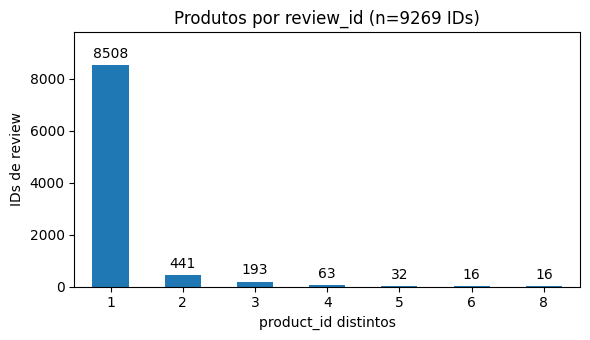

In [38]:
ax = produtos_por_review.value_counts().sort_index().plot.bar(rot=0, figsize=(6, 3.5))
ax.set(title=f'Produtos por review_id (n={len(produtos_por_review)} IDs)',
       xlabel='product_id distintos', ylabel='IDs de review')
ax.bar_label(ax.containers[0], padding=3)
ax.set_ylim(0, produtos_por_review.value_counts().max() * 1.15)
plt.tight_layout()
plt.show()

Há 11.503 ocorrências de 9.269 IDs; 761 aparecem em mais de um produto. Logo, contar
ocorrências e contar identificadores são operações diferentes.

### 6.3 — Pareamento posicional entre review e usuário
As duas listas poderiam estar alinhadas. Primeiro compararemos seus comprimentos;
somente as linhas compatíveis entram no pareamento por origem e posição. Depois
verificaremos se o mesmo review muda de usuário em outras ocorrências.

In [39]:
listas_compativeis = listas_reviews.str.len().eq(listas_usuarios.str.len())
pares_ids = reviews[reviews.source_index.isin(dados.index[listas_compativeis])].merge(
    usuarios[['source_index', 'posicao', 'user_id']], on=['source_index', 'posicao'], validate='one_to_one'
)
usuarios_por_review = pares_ids.groupby('review_id').user_id.nunique()
display(pd.Series({
    'linhas com comprimentos iguais': listas_compativeis.sum(),
    'pares posicionais examinados': len(pares_ids),
    'reviews examinados': len(usuarios_por_review),
    'reviews com usuários diferentes': usuarios_por_review.gt(1).sum()
}))
review_exemplo = produtos_por_review[produtos_por_review.gt(1)].index[0]
pares_ids[pares_ids.review_id.eq(review_exemplo)]

linhas com comprimentos iguais      1465
pares posicionais examinados       11503
reviews examinados                  9269
reviews com usuários diferentes        0
dtype: int64

,source_index,product_id,review_id,posicao,user_id
672,84,B07GVGTSLN,R10365HEDURWI9,1,AEXK37TSBFHSP2TYE63YPKETWQ7Q
2062,261,B07F1P8KNV,R10365HEDURWI9,1,AEXK37TSBFHSP2TYE63YPKETWQ7Q
7938,1010,B07GVGTSLN,R10365HEDURWI9,1,AEXK37TSBFHSP2TYE63YPKETWQ7Q


O pareamento é consistente nas 1.465 linhas: cada review observado mantém um único
usuário. Esse resultado sustenta o vínculo entre códigos; não associa automaticamente
um título ou comentário individual ao par.

### 6.4 — Limites da segmentação de títulos e conteúdos
Selecionamos um título com mais vírgulas do que seria esperado para uma lista paralela
de IDs. A contagem é somente um teste da hipótese de separação, não uma contagem de reviews.

In [40]:
quantidade_reviews = listas_reviews.str.len()
partes_titulo = dados.review_title.str.count(',') + 1
indice_titulo = dados.index[partes_titulo.gt(quantidade_reviews)][0]
display(dados.loc[indice_titulo, ['source_index', 'review_id', 'review_title']].to_frame('Valor').style.set_properties(
    **{'max-width': '660px', 'white-space': 'normal', 'overflow-wrap': 'anywhere', 'text-align': 'left'}
))

,Valor
source_index,8
review_id,"R1LW6NWSVTVZ2H,R3VR5WFKUS15C5,R2F6GC79OYWUKQ,R3QZ19MECGWG9A,R2MPU42MYK7GPO,R33DVXFB4VYPZZ,R1SQ7OGFR4JRUR,R1S5F9QI0M1VBZ"
review_title,"Works on linux for me. Get the model with antenna.,Does what it say but other brands available at lesser price,Easy Handle,Great product,Perfect working,Speed is perfect,Great Design, Build, Connectivity Range, Packaging and other features but no linux support since v2,Very good"


O título mostra vírgulas internas. No conteúdo, examinamos também um trecho com URL e comparamos a quantidade aparente de partes nos dois campos com a de IDs. Os blocos integrais permanecem na fonte.

In [41]:
tem_url = dados.review_content.str.contains(r'https?://', regex=True)
indice_url = dados.index[tem_url][0]
texto_url = dados.at[indice_url, 'review_content']
inicio_url = texto_url.find('http')
with pd.option_context('display.max_colwidth', None):
    display(dados.loc[[indice_url], ['source_index', 'product_id']].assign(
        inicio_trecho_exibicao=dados.loc[[indice_url], 'review_content'].str[:120],
        url_trecho_exibicao=texto_url[max(0, inicio_url - 30):inicio_url + 150]
    ))

,source_index,product_id,inicio_trecho_exibicao,url_trecho_exibicao
0,0,B07JW9H4J1,"Looks durable Charging is fine tooNo complains,Charging is really fast, good product.,Till now satisfied with the qualit","Good quality, would recommend,https://m.media-amazon.com/images/W/WEBP_402378-T1/images/I/81---F1ZgHL._SY88.jpg,Product had worked well till date and was having no issue.Cable is a"


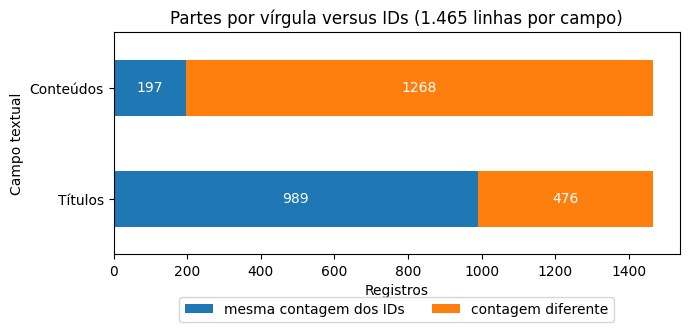

conteúdos com URL                233.0
menor conteúdo (caracteres)       67.0
mediana de caracteres            823.0
maior conteúdo (caracteres)    18547.0
dtype: float64

In [42]:
partes_conteudo = dados.review_content.str.count(',') + 1
comparacao_textos = pd.DataFrame({
    'mesma contagem dos IDs': [partes_titulo.eq(quantidade_reviews).sum(), partes_conteudo.eq(quantidade_reviews).sum()],
    'contagem diferente': [partes_titulo.ne(quantidade_reviews).sum(), partes_conteudo.ne(quantidade_reviews).sum()]
}, index=['Títulos', 'Conteúdos'])
fig, ax = plt.subplots(figsize=(7, 3.5))
comparacao_textos.plot.barh(stacked=True, ax=ax)
for barras in ax.containers:
    ax.bar_label(barras, label_type='center', color='white')
ax.set(title='Partes por vírgula versus IDs (1.465 linhas por campo)', xlabel='Registros', ylabel='Campo textual')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2)
plt.tight_layout()
plt.show()
display(pd.Series({
    'conteúdos com URL': tem_url.sum(),
    'menor conteúdo (caracteres)': dados.review_content.str.len().min(),
    'mediana de caracteres': dados.review_content.str.len().median(),
    'maior conteúdo (caracteres)': dados.review_content.str.len().max()
}))

As contagens coincidem em 989 títulos e apenas 197 conteúdos. Mesmo nesses casos,
igualdade de quantidades não comprova limites nem correspondência com os IDs. Vírgulas
internas, URLs e blocos longos tornam inadequada a segmentação automática por esse sinal.

### 6.5 — Reutilização e variação dos blocos textuais
O bloco será definido pelo par exato `review_title` + `review_content`. A hipótese é
que o mesmo bloco possa reaparecer em produtos diferentes. O teste preserva ambos os
campos completos e também conta conjuntos de IDs associados a cada par textual.

In [43]:
campos_texto = ['review_title', 'review_content']
blocos = dados.groupby(campos_texto, dropna=False, sort=False).agg(
    registros=('source_index', 'size'), produtos=('product_id', 'nunique'),
    listas_reviews=('review_id', 'nunique'), listas_usuarios=('user_id', 'nunique')
)
display(pd.Series({
    'blocos distintos (título + conteúdo)': len(blocos),
    'grupos textuais repetidos': blocos.registros.gt(1).sum(),
    'ocorrências nos grupos repetidos': blocos.loc[blocos.registros.gt(1), 'registros'].sum(),
    'grupos textuais entre produtos': blocos.produtos.gt(1).sum(),
    'blocos ligados a várias listas de review_id': blocos.listas_reviews.gt(1).sum(),
    'blocos ligados a várias listas de user_id': blocos.listas_usuarios.gt(1).sum()
}))
chave_bloco = blocos[blocos.produtos.gt(1)].index[0]
exemplo_bloco = dados[dados.review_title.eq(chave_bloco[0]) & dados.review_content.eq(chave_bloco[1])]
with pd.option_context('display.max_colwidth', None):
    display(exemplo_bloco[['source_index', 'product_id']].assign(
        mesma_lista_review_id=exemplo_bloco.review_id.eq(exemplo_bloco.review_id.iloc[0]),
        conteudo_trecho_exibicao=exemplo_bloco.review_content.str[:130]
    ))

blocos distintos (título + conteúdo)           1212
grupos textuais repetidos                       141
ocorrências nos grupos repetidos                394
grupos textuais entre produtos                   96
blocos ligados a várias listas de review_id       0
blocos ligados a várias listas de user_id         0
dtype: int64

,source_index,product_id,mesma_lista_review_id,conteudo_trecho_exibicao
0,0,B07JW9H4J1,True,"Looks durable Charging is fine tooNo complains,Charging is really fast, good product.,Till now satisfied with the quality.,This is"
42,42,B07JW1Y6XV,True,"Looks durable Charging is fine tooNo complains,Charging is really fast, good product.,Till now satisfied with the quality.,This is"
106,106,B07JGDB5M1,True,"Looks durable Charging is fine tooNo complains,Charging is really fast, good product.,Till now satisfied with the quality.,This is"


Os 141 grupos repetidos reúnem 394 ocorrências e 96 grupos atravessam produtos. Cada par textual integral observado acompanha uma só combinação de listas de usuário e review. No sentido inverso, a mesma lista de reviews pode acompanhar versões textuais distintas. Examinamos o primeiro caso pela ordem da fonte.

In [44]:
textos_por_lista = dados[['review_id'] + campos_texto].drop_duplicates().groupby('review_id').size()
display(textos_por_lista.value_counts().sort_index().rename_axis('Blocos textuais por lista completa de review_id').rename('Listas'))
lista_exemplo = textos_por_lista[textos_por_lista.gt(1)].index[0]
versoes_texto = dados[dados.review_id.eq(lista_exemplo)].drop_duplicates(campos_texto)
with pd.option_context('display.max_colwidth', None):
    display(versoes_texto[['source_index', 'product_id']].assign(
        titulo_trecho_exibicao=versoes_texto.review_title.str[:70],
        caracteres_conteudo=versoes_texto.review_content.str.len(),
        final_conteudo_trecho_exibicao=versoes_texto.review_content.str[-160:]
    ))

Blocos textuais por lista completa de review_id
1    1180
2      10
3       4
Name: Listas, dtype: int64

,source_index,product_id,titulo_trecho_exibicao,caracteres_conteudo,final_conteudo_trecho_exibicao
426,426,B08MTCKDYN,"Awesome Product,Good product,Good quality,Good but overpriced,Gud qual",500,"slightly expensive.,https://m.media-amazon.com/images/I/61W2kONTcaL._SY88.jpg,Ok,Using this for my mobile charging cable it’s useful for not to brake the cable"
672,672,B08MTCKDYN,"Awesome Product,Good product,Good quality,Good but overpriced,Gud qual",548,"ps://m.media-amazon.com/images/W/WEBP_402378-T1/images/I/61W2kONTcaL._SY88.jpg,Ok,Using this for my mobile charging cable it’s useful for not to brake the cable"


Uma lista de IDs pode acompanhar versões textuais diferentes. No exemplo, a diferença inclui a representação de uma URL de mídia; não demonstra mudança de opinião nem uma nova data de captura. O vínculo recuperável é
entre a linha, a lista e o bloco preservado; não há base para distribuir frases entre
reviews individuais. Reutilização também pode repetir evidências em análises textuais.

### 6.6 — Diferença entre contagem agregada e reviews identificados
Reaproveitamos a conversão de `rating_count` e comparamos com a quantidade de IDs de
review por linha. Os menores valores válidos permitem observar casos de igualdade e
diferença sem reduzir a investigação aos maiores extremos.

In [45]:
comparacao_contagem = dados[['source_index', 'product_id', 'rating_count']].assign(
    contagem=numeros.rating_count, ids_disponiveis=quantidade_reviews
)
display(comparacao_contagem.sort_values('contagem').head(5))
validas_contagem = numeros.rating_count.notna()
pd.Series({
    'linhas com contagem válida': validas_contagem.sum(),
    'contagem maior que IDs': (numeros.rating_count.gt(quantidade_reviews) & validas_contagem).sum(),
    'contagem igual a IDs': (numeros.rating_count.eq(quantidade_reviews) & validas_contagem).sum(),
    'contagem menor que IDs': (numeros.rating_count.lt(quantidade_reviews) & validas_contagem).sum()
})

,source_index,product_id,rating_count,contagem,ids_disponiveis
1459,1459,B0B3JSWG81,2,2.0,1
1309,1309,B0BPJBTB3F,2,2.0,2
1385,1385,B0BL3R4RGS,4,4.0,2
1070,1070,B0BGPN4GGH,4,4.0,3
1344,1344,B0BNLFQDG2,4,4.0,3


linhas com contagem válida    1463
contagem maior que IDs        1461
contagem igual a IDs             2
contagem menor que IDs           0
dtype: int64

Em 1.461 das 1.463 linhas válidas, a contagem agregada supera a quantidade de IDs disponíveis. Essas unidades medem coisas diferentes, e a comparação não permite inferir representatividade, notas individuais ou autoria. Nos Notebooks 04 e 05, o bloco integral preserva o contexto e os grupos exatos ajudam a controlar repetições e dependências. Resta verificar o que as referências digitais acrescentam à identidade.

## 7 — Referências digitais e identidade
### 7.1 — Links dos produtos e consistência dos identificadores
O caminho após `/dp/` aponta para o mesmo código mesmo quando variam os parâmetros? Retomamos um ID repetido e confrontamos os códigos extraídos com `product_id` em toda a fonte.

In [46]:
exemplo_links = dados.loc[dados.product_id.eq(ids_repetidos.index[0]),
                          ['source_index', 'product_id', 'product_name', 'product_link', 'img_link']]
display(exemplo_links[['source_index', 'product_id']].assign(
    trecho_apos_dp=exemplo_links.product_link.str.split('/dp/', regex=False).str[-1].str.slice(0, 85)
))
id_no_link = dados.product_link.str.extract(r'/dp/([A-Z0-9]{10})(?:[/?]|$)', expand=False)
pd.Series({
    'IDs extraídos': id_no_link.notna().sum(),
    'coincidências com product_id': id_no_link.eq(dados.product_id).sum(),
    'URLs completas distintas': dados.product_link.nunique(),
    'IDs repetidos com URLs divergentes': conflitos['product_link']
})

,source_index,product_id,trecho_apos_dp
0,0,B07JW9H4J1,B07JW9H4J1/ref=sr_1_1?qid=1672909124&s=electro...
369,369,B07JW9H4J1,B07JW9H4J1/ref=sr_1_38?qid=1672895755&s=electr...
614,614,B07JW9H4J1,B07JW9H4J1/ref=sr_1_33?qid=1672902996&s=comput...


IDs extraídos                         1465
coincidências com product_id          1465
URLs completas distintas              1465
IDs repetidos com URLs divergentes      92
dtype: int64

Todos os códigos extraídos coincidem. URLs inteiras distinguem as linhas, mas seus
parâmetros não criam novos produtos identificados.

### 7.2 — Imagens, compartilhamento e limites de identidade
Uma imagem poderia auxiliar a identidade? Testaremos variações dentro do ID e
compartilhamento entre IDs. Selecionamos a URL associada ao maior número de produtos,
incluindo o caso com três códigos distintos.

In [47]:
produtos_por_imagem = dados.groupby('img_link').product_id.nunique()
imagens_compartilhadas = produtos_por_imagem[produtos_por_imagem.gt(1)]
display(pd.Series({
    'URLs de imagem distintas': len(produtos_por_imagem),
    'IDs repetidos com URLs de imagem divergentes': conflitos['img_link'],
    'URLs compartilhadas entre produtos': len(imagens_compartilhadas),
    'produtos nessas URLs': dados.loc[dados.img_link.isin(imagens_compartilhadas.index), 'product_id'].nunique()
}))
exemplo_imagem = dados.loc[dados.img_link.eq(produtos_por_imagem.idxmax()),
                           ['source_index', 'product_id', 'product_name', 'img_link']]
with pd.option_context('display.max_colwidth', None):
    display(exemplo_imagem[['source_index', 'product_id']].assign(
        nome_trecho_exibicao=exemplo_imagem.product_name.str[:90],
        mesma_url_imagem=exemplo_imagem.img_link.eq(exemplo_imagem.img_link.iloc[0])
    ))

URLs de imagem distintas                        1412
IDs repetidos com URLs de imagem divergentes      77
URLs compartilhadas entre produtos                25
produtos nessas URLs                              51
dtype: int64

,source_index,product_id,nome_trecho_exibicao,mesma_url_imagem
399,399,B0B4F3QNDM,"Samsung Galaxy M13 5G (Aqua Green, 6GB, 128GB Storage) | 5000mAh Battery | Upto 12GB RAM w",True
425,425,B0B4F5L738,"Samsung Galaxy M13 5G (Aqua Green, 6GB, 128GB Storage) | 5000mAh Battery | Upto 12GB RAM w",True
481,481,B0B4F1YC3J,"Samsung Galaxy M13 5G (Aqua Green, 6GB, 128GB Storage) | 5000mAh Battery | Upto 12GB RAM w",True


Há 25 URLs de imagem compartilhadas por 51 produtos e variações de URL dentro de 77 IDs repetidos. A URL ajuda a rastrear a referência digital, mas não resolve equivalência comercial ou visual. Com os limites de cada campo estabelecidos, podemos reunir as unidades e relações observadas.

## 8 — Granularidade geral, relações e transição para o tratamento
### 8.1 — Registros físicos e unidades analíticas
Cada posição é uma ocorrência de catálogo. A partir dela recuperamos produto, caminho de categoria, códigos posicionais e bloco textual. O inventário distingue essas unidades antes de comparar suas consequências.

In [48]:
display(pd.Series({
    'Registros físicos': len(dados), 'Produtos': dados.product_id.nunique(),
    'Caminhos completos': dados.category.nunique(), 'Usuários por código': usuarios.user_id.nunique(),
    'Reviews por código': reviews.review_id.nunique(), 'Pares posicionais': len(pares_ids),
    'Blocos textuais exatos': len(blocos)
}, name='Quantidade').to_frame())

,Quantidade
Registros físicos,1465
Produtos,1351
Caminhos completos,211
Usuários por código,9050
Reviews por código,9269
Pares posicionais,11503
Blocos textuais exatos,1212


### 8.2 — Impacto da granularidade nas estatísticas
Quanto muda a mediana ao dar o mesmo peso a cada produto? Retomamos o ID com mais ocorrências e comparamos todas as linhas com a primeira por ID. A seleção pela ordem da fonte é um cenário diagnóstico, distinto da referência comercial escolhida no tratamento.

In [49]:
dados.loc[dados.product_id.eq(frequencia.idxmax()), ['source_index', 'product_id'] + campos_medidas]

,source_index,product_id,actual_price,discounted_price,discount_percentage,rating,rating_count
0,0,B07JW9H4J1,"₹1,099",₹399,64%,4.2,"24,269"
369,369,B07JW9H4J1,"₹1,099",₹399,64%,4.2,"24,270"
614,614,B07JW9H4J1,"₹1,099",₹399,64%,4.2,"24,269"


,actual_price,discounted_price,discount_percentage
Linhas originais (n=1465),1650.0,799.0,50.0
Primeira por ID (n=1351),1795.0,899.0,49.0


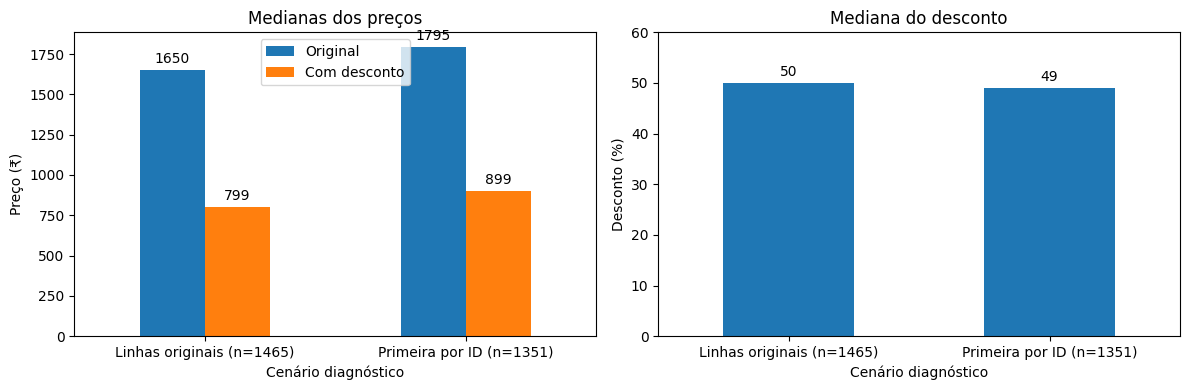

In [50]:
primeiras = ~dados.product_id.duplicated(keep='first')
medianas = pd.DataFrame({
    f'Linhas originais (n={len(dados)})': numeros[campos_medidas[:3]].median(),
    f'Primeira por ID (n={primeiras.sum()})': numeros.loc[primeiras, campos_medidas[:3]].median()
}).T
display(medianas)
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
medianas[['actual_price', 'discounted_price']].rename(columns={
    'actual_price': 'Original', 'discounted_price': 'Com desconto'
}).plot.bar(ax=eixos[0], rot=0)
eixos[0].set(title='Medianas dos preços', ylabel='Preço (₹)', xlabel='Cenário diagnóstico')
medianas.discount_percentage.plot.bar(ax=eixos[1], rot=0)
eixos[1].set(title='Mediana do desconto', ylabel='Desconto (%)', xlabel='Cenário diagnóstico', ylim=(0, 60))
for ax in eixos:
    for barras in ax.containers:
        ax.bar_label(barras, padding=3, fmt='%g')
plt.tight_layout()
plt.show()

As medianas passam de ₹1.650 para ₹1.795 no preço original, de ₹799 para ₹899 no preço
com desconto e de 50% para 49% no percentual. A diferença combina mudança de peso e
seleção de uma versão por ID; não isola esses dois efeitos nem valida a primeira
ocorrência como tratamento. As 1.465 linhas continuam preservadas.

### 8.3 — Modelo conceitual e relacionamentos observados
A ocorrência reúne os atributos observados e permite recuperar os pares posicionais. O diagrama separa a estrutura testada da camada comercial proposta. A tabela especifica as cardinalidades e os limites de atribuição textual.

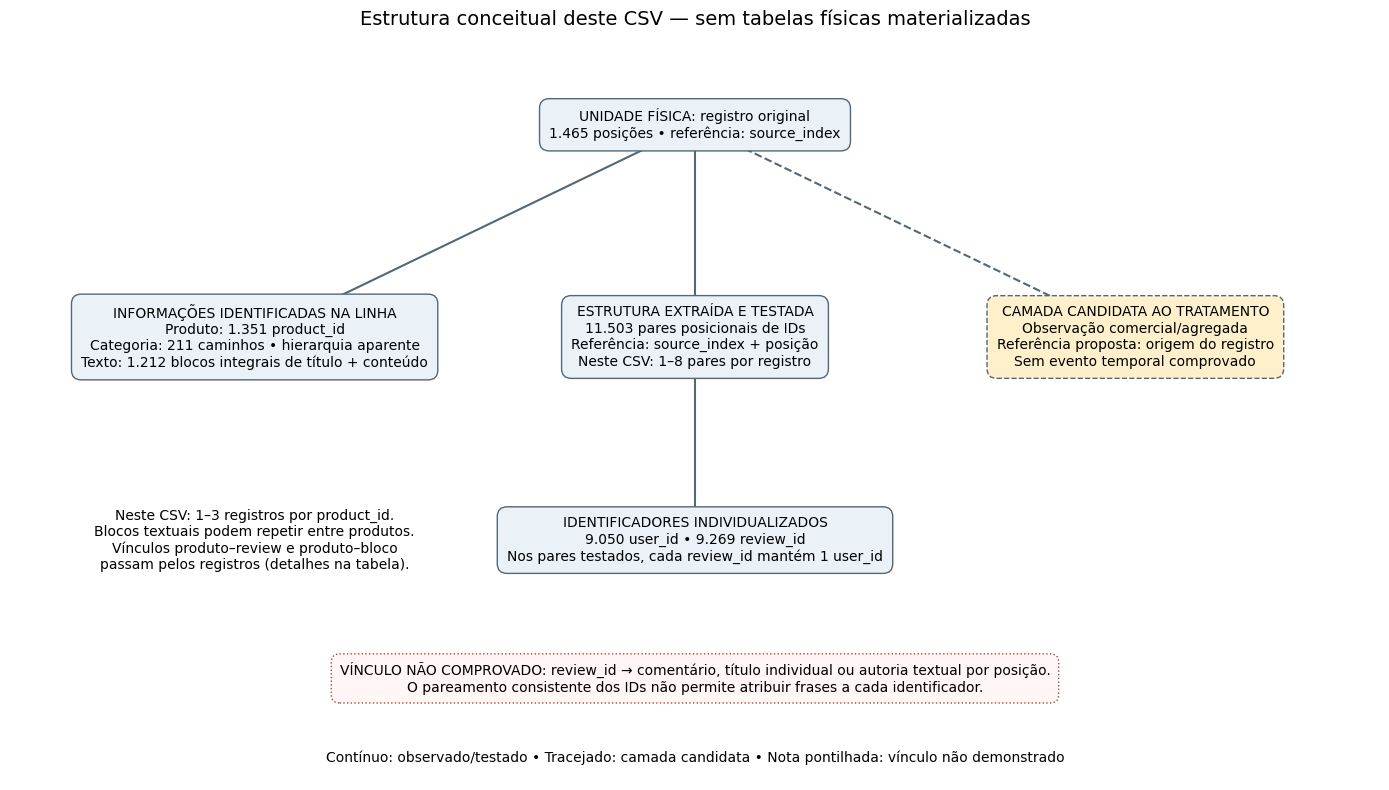

In [51]:
fig, ax = plt.subplots(figsize=(14, 8))
ax.set(xlim=(0, 14), ylim=(0, 8))
ax.axis('off')
caixas = {
    'registro': (7, 7.1, 'UNIDADE FÍSICA: registro original\n1.465 posições • referência: source_index'),
    'identificados': (2.5, 4.8, 'INFORMAÇÕES IDENTIFICADAS NA LINHA\nProduto: 1.351 product_id\nCategoria: 211 caminhos • hierarquia aparente\nTexto: 1.212 blocos integrais de título + conteúdo'),
    'pares': (7, 4.8, 'ESTRUTURA EXTRAÍDA E TESTADA\n11.503 pares posicionais de IDs\nReferência: source_index + posição\nNeste CSV: 1–8 pares por registro'),
    'observacao': (11.5, 4.8, 'CAMADA CANDIDATA AO TRATAMENTO\nObservação comercial/agregada\nReferência proposta: origem do registro\nSem evento temporal comprovado'),
    'ids': (7, 2.6, 'IDENTIFICADORES INDIVIDUALIZADOS\n9.050 user_id • 9.269 review_id\nNos pares testados, cada review_id mantém 1 user_id')
}
arestas = [('registro', 'identificados'), ('registro', 'pares'),
           ('registro', 'observacao'), ('pares', 'ids')]
for origem, destino in arestas:
    x1, y1, _ = caixas[origem]
    x2, y2, _ = caixas[destino]
    ax.plot([x1, x2], [y1, y2], color='#536777', zorder=0,
            linestyle='--' if destino == 'observacao' else '-')
for nome, (x, y, texto) in caixas.items():
    candidato = nome == 'observacao'
    ax.text(x, y, texto, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.7', facecolor='#fff0cc' if candidato else '#eaf2f8',
                      edgecolor='#536777', linestyle='--' if candidato else '-'))
ax.text(2.5, 2.6, 'Neste CSV: 1–3 registros por product_id.\nBlocos textuais podem repetir entre produtos.\nVínculos produto–review e produto–bloco\npassam pelos registros (detalhes na tabela).',
        ha='center', va='center', fontsize=10)
ax.text(7, 1.1, 'VÍNCULO NÃO COMPROVADO: review_id → comentário, título individual ou autoria textual por posição.\nO pareamento consistente dos IDs não permite atribuir frases a cada identificador.',
        ha='center', va='center', fontsize=10, bbox=dict(boxstyle='round,pad=0.6',
        facecolor='#fff6f5', edgecolor='#a34842', linestyle=':'))
ax.text(7, 0.2, 'Contínuo: observado/testado • Tracejado: camada candidata • Nota pontilhada: vínculo não demonstrado',
        ha='center', fontsize=10)
ax.set_title('Estrutura conceitual deste CSV — sem tabelas físicas materializadas', fontsize=14, pad=12)
plt.tight_layout()
plt.show()

| Unidade / entidade | Chave ou referência candidata | Grão e relações observadas | Limite |
|---|---|---|---|
| Registro original | `source_index` | 1.465 posições; uma linha por posição | Posição vale para este arquivo e sua ordem |
| Produto identificado | `product_id` | Neste CSV: 1.351 IDs, 1–3 registros por ID | Equivalência comercial entre IDs não confirmada |
| Observação comercial/agregada | origem do registro | Uma observação por linha como camada candidata; produto 1:N observações | Sem data ou regra de consolidação |
| Categoria | caminho completo | 211 caminhos; um caminho por ID observado; categoria 1:N produtos | Taxonomia aparente, profundidade 2–7 |
| Par posicional | `source_index` + posição | 11.503 ocorrências; neste CSV, 1–8 pares por registro | Código consistente não comprova semântica do texto |
| ID de usuário | `user_id` separado | 9.050 IDs; cada review testado mantém um usuário | Não equivale a pessoa ou comprador confirmado |
| ID de review | `review_id` separado | 9.269 IDs; produto N:N reviews; usuário 1:N reviews | Texto individual não recuperável por vírgula |
| Comentário individual | Nenhuma chave recuperada | Relação com review individual não comprovada | Não atribuir frases, títulos ou autoria a um ID |
| Bloco textual | par integral título + conteúdo | 1.212 pares; registro N:1 bloco; produto N:N blocos | Chave física futura ainda não definida |

O diagrama agrupa produto, categoria e bloco textual como informações identificadas
na linha; a tabela explicita seus vínculos por meio dos registros. Compartilhar texto
não torna os produtos idênticos. A eventual camada de observações é uma escolha de modelagem,
não uma entidade temporal descoberta no CSV.

### 8.4 — Riscos e diretrizes para o tratamento
| Evidência | Consequência concreta | Diretriz para decisão posterior |
|---|---|---|
| ID repetido e medidas/descrições divergentes | Supercontagem ou perda de versões | Preservar observações e definir regra por atributo |
| 13 campos, nome ou imagem iguais entre IDs | Fusão indevida de variantes | Manter códigos distintos sem evidência adicional |
| Profundidade variável e ramos pequenos | Comparações em níveis incompatíveis | Guardar caminho e declarar nível e denominador |
| Nota inválida e contagens ausentes | Zero ou valor imputado artificial | Manter literal e marcar falha/ausência na preparação |
| Nomes ambíguos/compartilhados e pares posicionais de IDs | Atribuição nominal ou textual incorreta | Conservar origem e posição; limitar cada vínculo à evidência |
| Blocos inseparáveis e reutilizados | Contagem falsa de reviews e repetição de evidência textual | Preservar bloco; decidir unidade de análise e controle de repetição |

### 8.5 — Fatos, hipóteses e encaminhamento para o Notebook 02
Os testes demonstram repetição de IDs, variação de medidas, estabilidade de caminhos por produto e consistência posicional entre códigos de usuário e review. A equivalência comercial entre códigos, a cronologia e a autoria individual dos trechos permanecem indeterminadas.

| Evidência estrutural | Implementação posterior no Notebook 02 |
|---|---|
| Posição original e versões dos atributos | `ocorrencias_catalogo` conserva todas as linhas, textos integrais, origem e grupo textual. |
| Identidade e classificação estável por código | `produtos` mantém um registro por ID, com caminho completo e referência comercial a uma ocorrência. |
| Código de usuário separável e limites dos nomes | `usuarios` consolida códigos e sinaliza a situação dos nomes. |
| Código de review e usuário consistente nos pares testados | `avaliacoes_identificadas` organiza um registro por ID de review, com vínculo ao código de usuário. |
| Pareamento pela origem e posição | `vinculos_avaliacoes` preserva os pares e liga os reviews às ocorrências. |

A projeção `textos_avaliacoes` atende consumidores legados a partir das ocorrências. A escolha da referência, as conversões definitivas e a organização física pertencem ao Notebook 02. A sensibilidade da seção 8.2 ilustra o efeito da unidade analítica.